## Output Analysis Development
Use this notebook for initial assessment of model output and development of automated analysis scripts.

In [1]:
path_env = 'desktop'  # Change this to 'desktop' or 'alpine' as needed

In [2]:
import os

# Configure environmental variables
if path_env == 'desktop':
    os.environ['OUTPUT_PATH'] = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    os.environ['SNOTEL_PATH'] = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
    os.environ['FORCING_PATH'] = 'C:/Users/clmbn/NMT_PhD/data/forcing/' #desktop
elif path_env == 'alpine':
    os.environ['OUTPUT_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    os.environ['SNOTEL_PATH'] = r'/projects/ccox1@xsede.org/data/snotel/'
    os.environ['FORCING_PATH'] = r'/projects/ccox1@xsede.org/data/forcing/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

In [3]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from model_datasets.forcing import LM4Forcing
from model_datasets.output import LM4ModelOutput 
from buildforcing.datasets import PNNLSnotel

Load datasets

In [4]:
forcing = LM4Forcing(site='Quemazon', forcing_string='00000000', version='0.2', spinup=False)
#forcing2 = LM4Forcing(site='Quemazon', forcing_string='00000000', version='0.2', spinup=False)

In [9]:
model = LM4ModelOutput(site='Quemazon', forcing_string='00000000', namelist='cmbc', version='0.2.1', spinup=False)
model2 = LM4ModelOutput(site='Quemazon', forcing_string='00000000', namelist='gbc', version='0.2.1', spinup=False)

In [10]:
daily_vars = model.get_variables(diag='land_daily')

In [11]:
monthly_vars = model.get_variables(diag='land_month')

In [12]:
snotel = PNNLSnotel('Quemazon', os.environ['SNOTEL_PATH'])
snotel.load_data()

In [13]:
snotel_data = snotel.data

# Remove timezone from index
snotel_data.index = snotel_data.index.tz_localize(None)

### Snow

In [14]:
model_snow = model.get_data(['snow','snow_depth'],'land_daily')
model2_snow = model2.get_data(['snow','snow_depth'],'land_daily')

In [16]:
snotel.data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
1980-06-04,NaN,NaN,NaN,0.0,NaN
1980-06-05,NaN,NaN,NaN,0.0,NaN
1980-06-06,NaN,NaN,NaN,0.0,NaN
1980-06-07,NaN,NaN,NaN,0.0,NaN
1980-06-08,NaN,NaN,NaN,0.0,NaN


In [15]:
# Get range of dates for plotting
start_date = model_snow.index[0]
end_date = model_snow.index[-1]

In [ ]:
snotel.data.index

In [17]:
Tair = forcing.get_data('Tair')
Snowfall = forcing.get_data('Snowf')

Tair = Tair - 273.15  # Convert from Kelvin to Celsius

Tair_daily = Tair.resample('D').mean()
forcing_snow = Snowfall.resample('D').sum()

In [18]:
Tair2 = forcing2.get_data('Tair')
Snowfall2 = forcing2.get_data('Snowf')

Tair2 = Tair2 - 273.15  # Convert from Kelvin to Celsius

Tair_daily2 = Tair2.resample('D').mean()
forcing_snow2 = Snowfall2.resample('D').sum()

NameError: name 'forcing2' is not defined

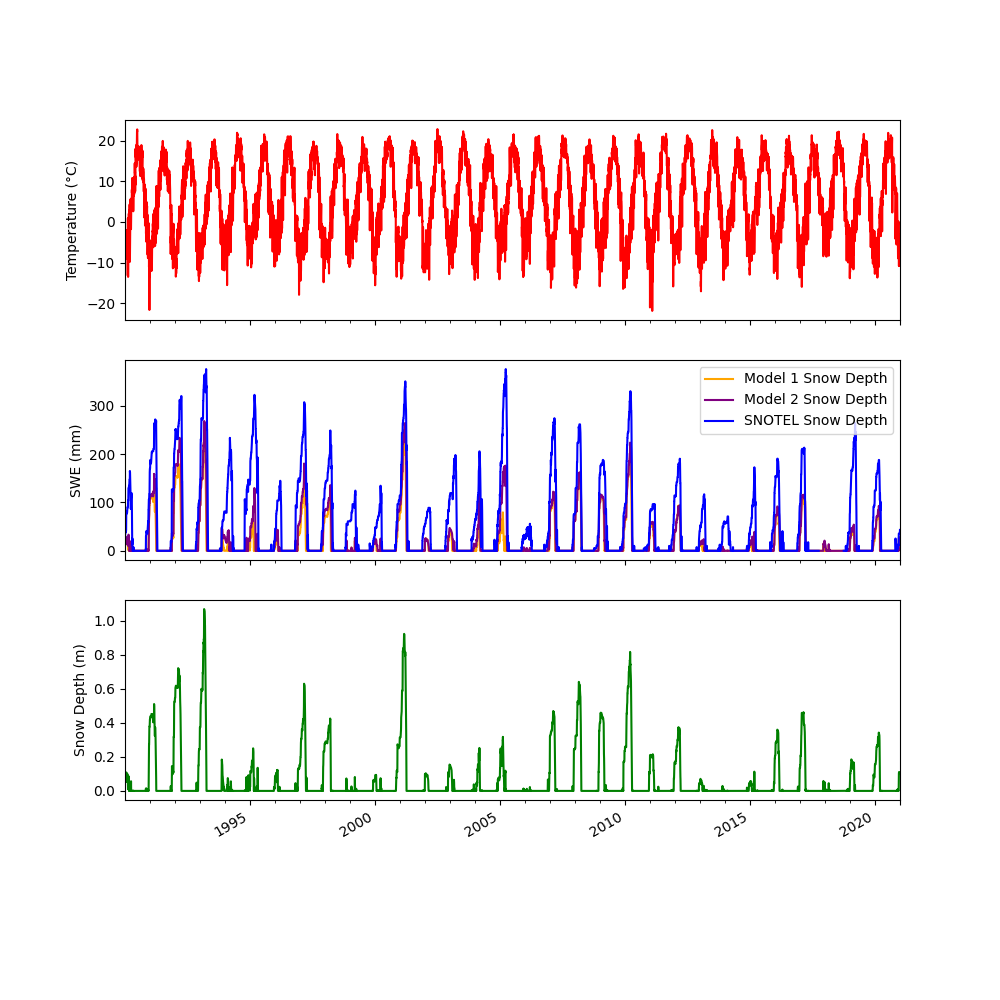

In [20]:
# Plot snow
fig, ax = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
Tair_daily.plot(ax=ax[0], label='Tair (Daily Mean)', color='red')
#Tair_daily2.plot(ax=ax[0], label='Tair2 (Daily Mean)', style='--', color='red')
model_snow['snow'].plot(ax=ax[1], label='Model 1 Snow Depth', color='orange')
model2_snow['snow'].plot(ax=ax[1], label='Model 2 Snow Depth', color='purple')
snotel_data.loc[start_date:end_date, 'swe_mm'].plot(ax=ax[1], label='SNOTEL Snow Depth', color='blue')
model_snow['snow_depth'].plot(ax=ax[2], label='Model Snow Depth (Depth)', color='green')
ax[0].set_ylabel('Temperature (°C)')
ax[1].set_ylabel('SWE (mm)')
ax[2].set_ylabel('Snow Depth (m)')
ax[1].legend()

### Bias and RMSE for snow depth and SWE


In [23]:
# Combine daily snow datasets into a single frame for analysis
snow_data = pd.merge(
    model_snow['snow'],
    model2_snow['snow'],
    left_index=True, right_index=True, suffixes=('_model1', '_model2')
)

In [25]:
snotel_swe = snotel_data.loc[start_date:end_date, 'swe_mm']
snotel_swe.index = snotel_swe.index + pd.Timedelta(hours=12)  # Adjust SNOTEL data to match model time
snow_data = pd.merge(
    snow_data,
    snotel_swe,
    left_index=True, right_index=True, suffixes=('', '_snotel')
)

In [27]:
# Calculate bias and RMSE
snow_data.dropna(inplace=True)  # Ensure no NaN values in data
bias_model1 = (snow_data['snow_model1'] - snow_data['swe_mm']).mean()
bias_model2 = (snow_data['snow_model2'] - snow_data['swe_mm']).mean()
rmse_model1 = ((snow_data['snow_model1'] - snow_data['swe_mm']) ** 2).mean() ** 0.5
rmse_model2 = ((snow_data['snow_model2'] - snow_data['swe_mm']) ** 2).mean() ** 0.5

# Print bias and RMSE
print(f"Model 1 Bias: {bias_model1:.2f} mm, RMSE: {rmse_model1:.2f} mm")
print(f"Model 2 Bias: {bias_model2:.2f} mm, RMSE: {rmse_model2:.2f} mm")

Model 1 Bias: -35.31 mm, RMSE: 67.82 mm
Model 2 Bias: -30.10 mm, RMSE: 56.42 mm
